In [1]:
import pickle
import pandas as pd
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
import os

**Load in rec info using dataframes**

In [2]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/GWAS_rec_info_CONGEN_HEART_ARTER_CT20211117.pickle', 'rb')
rec_info_CONGEN_HEART_ARTER=pickle.load(pickle_in)

In [3]:
snp_id = rec_info_CONGEN_HEART_ARTER[0][0]
chrm = rec_info_CONGEN_HEART_ARTER[0][1]
start = rec_info_CONGEN_HEART_ARTER[0][2]
end = rec_info_CONGEN_HEART_ARTER[0][3]
rec_info = {'snp_id': snp_id, 'chrm': chrm, 'start':start, 'end':end}
CONGEN_HEART_ARTER_df = pd.DataFrame(rec_info)
# test_df = CONGEN_HEART_ARTER_df[:5]
# test_df['start'] = pd.to_numeric(test_df['start'])
# test_df['end'] = pd.to_numeric(test_df['end'])
# test_df.head()
CONGEN_HEART_ARTER_df['start'] = pd.to_numeric(CONGEN_HEART_ARTER_df['start'])
CONGEN_HEART_ARTER_df['end'] = pd.to_numeric(CONGEN_HEART_ARTER_df['end'])
CONGEN_HEART_ARTER_df

,snp_id,chrm,start,end
0,rs556642707,chr16,67660381,67660382
1,rs554751435,chr16,67668273,67668274
2,rs559342068,chr15,84839995,84839996
3,rs77815840,chr19,50802454,50802455
4,rs546358522,chr12,121814441,121814442
...,...,...,...,...
2089216,rs75878186,chr4,17855630,17855631
2089217,rs16896261,chr4,18009579,18009580
2089218,4:17817687_AT_A,chr4,17816064,17816065
2089219,rs7740188,chr6,130024960,130024961


In [9]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['start'] = pd.to_numeric(DHS_metadata['start'])
DHS_metadata['end'] = pd.to_numeric(DHS_metadata['end'])
DHS_metadata.head()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
0,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
1,chr1,51868,52040,1.10021,0.0800339,1,51970,51970,51970,Placental / trophoblast
2,chr1,57280,57354,1.10025,0.2732505,4,57350,57350,57350,Neural
3,chr1,66370,66482,1.10027,0.183715575,8,66430,66410,66430,Primitive / embryonic
4,chr1,79100,79231,1.1003,0.113049,2,79150,79150,79150,Placental / trophoblast


In [9]:
chromosomes = pd.unique(CONGEN_HEART_ARTER_df['chrm'])
chromosomes = chromosomes[:23]
chromosomes

array(['chr16', 'chr15', 'chr19', 'chr12', 'chr8', 'chr11', 'chr9',
       'chr21', 'chrX', 'chr13', 'chr2', 'chr1', 'chr17', 'chr6', 'chr20',
       'chr3', 'chr4', 'chr5', 'chr10', 'chr14', 'chr7', 'chr22', 'chr18'],
      dtype=object)

In [6]:
division = 100
overlap = 5000

In [7]:
#merging by sections of each chromosome to conserve memory
chrm_dataframes = []
for chromosome in chromosomes:
    print('Chromosome:', chromosome)
    DHS_metadata_df_chrm = DHS_metadata[(DHS_metadata['seqname']==chromosome)]
    CONGEN_HEART_ARTER_df_chrm = CONGEN_HEART_ARTER_df[(CONGEN_HEART_ARTER_df['chrm']==chromosome)]
    start_over_100 = round(CONGEN_HEART_ARTER_df_chrm.iloc[-1]['start']/division)
    for i in range(division):
#         print(i)
        CONGEN_HEART_ARTER_df_chrm_iter = CONGEN_HEART_ARTER_df_chrm[(CONGEN_HEART_ARTER_df_chrm['start']<((i+1)*start_over_100+overlap)) & (CONGEN_HEART_ARTER_df_chrm['start']>=(i*start_over_100-overlap))]
        DHS_metadata_df_chrm_iter = DHS_metadata_df_chrm[(DHS_metadata_df_chrm['start']<((i+1)*start_over_100+overlap)) & (DHS_metadata_df_chrm['start']>=(i*start_over_100-overlap))]
        combined_df = pd.merge(CONGEN_HEART_ARTER_df_chrm_iter, DHS_metadata_df_chrm_iter,  how='inner', left_on='chrm', right_on = 'seqname')
        combined_df = combined_df[combined_df['start_x'] > combined_df['start_y']]
        combined_df = combined_df[combined_df['end_x'] < combined_df['end_y']]
        chrm_dataframes.append(combined_df)
all_chrm_df = pd.concat(chrm_dataframes)

Chromosome: chr16
Chromosome: chr15
Chromosome: chr19
Chromosome: chr12
Chromosome: chr8
Chromosome: chr11
Chromosome: chr9
Chromosome: chr21
Chromosome: chrX
Chromosome: chr13
Chromosome: chr2
Chromosome: chr1
Chromosome: chr17
Chromosome: chr6
Chromosome: chr20
Chromosome: chr3
Chromosome: chr4
Chromosome: chr5
Chromosome: chr10
Chromosome: chr14
Chromosome: chr7
Chromosome: chr22
Chromosome: chr18


In [26]:
all_chrm_df

,snp_id,chrm,start_x,end_x,seqname,start_y,end_y,identifier,mean_signal,numsamples,summit,core_start,core_end,component
459,rs367783075,chr16,270573,270574,chr16,270400,270791,16.102753,0.208709,6,270650,270442.0,270766.0,Primitive / embryonic
1343,rs201357046,chr16,180982,180983,chr16,180960,181217,16.101874,0.647074,141,181070,181020.0,181170.0,Stromal B
1804,rs78153988,chr16,166081,166082,chr16,165860,166120,16.101715,1.593566,19,165990,165906.0,166083.0,Myeloid / erythroid
2980,rs377431546,chr16,275483,275484,chr16,275460,275686,16.102812,0.413114,9,275550,275514.0,275590.0,Neural
3948,rs542200430,chr16,264141,264142,chr16,263960,264260,16.102681,0.112398,1,264130,264130.0,264130.0,Lymphoid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140324,rs11874453,chr18,23170436,23170437,chr18,23170230,23170480,18.359467,0.734062,4,23170360,23170332.0,23170388.0,Primitive / embryonic
141520,rs4308051,chr18,23155497,23155498,chr18,23155420,23155820,18.359311,0.506168,5,23155610,23155590.0,23155630.0,Organ devel. / renal
144404,rs4369779,chr18,23155444,23155445,chr18,23155420,23155820,18.359311,0.506168,5,23155610,23155590.0,23155630.0,Organ devel. / renal
146453,rs4420634,chr18,23150584,23150585,chr18,23150560,23150700,18.359245,0.24721,1,23150610,23150610.0,23150610.0,Musculoskeletal


In [10]:
CONGEN_HEART_ARTER_df['rank'] = CONGEN_HEART_ARTER_df.index
CONGEN_HEART_ARTER_ranks = CONGEN_HEART_ARTER_df[['rank', 'snp_id']]
CONGEN_HEART_ARTER_ranks

,rank,snp_id
0,0,rs556642707
1,1,rs554751435
2,2,rs559342068
3,3,rs77815840
4,4,rs546358522
...,...,...
2089216,2089216,rs75878186
2089217,2089217,rs16896261
2089218,2089218,4:17817687_AT_A
2089219,2089219,rs7740188


In [11]:
CONGEN_HEART_ARTER_ranked_SNP_recs_DHS_merged = pd.merge(all_chrm_df, CONGEN_HEART_ARTER_ranks,  how='inner', left_on='snp_id', right_on = 'snp_id')

In [12]:
CONGEN_HEART_ARTER_ranked_SNP_recs_DHS_merged = CONGEN_HEART_ARTER_ranked_SNP_recs_DHS_merged.sort_values(by=['rank'])
CONGEN_HEART_ARTER_ranked_SNP_recs_DHS_merged

,snp_id,chrm,start_x,end_x,seqname,start_y,end_y,identifier,mean_signal,numsamples,summit,core_start,core_end,component,rank
51044,rs546358522,chr12,121814441,121814442,chr12,121814402,121815020,12.9224797,0.26976,3,121814630,121814611.0,121814744.0,Placental / trophoblast,4
37614,rs200766710,chr12,53504730,53504731,chr12,53504126,53504820,12.4612992,0.25579,3,53504600,53504552.0,53504760.0,Musculoskeletal,6
46128,rs560473142,chr12,104309927,104309928,chr12,104309853,104310100,12.804293,0.518231,1,104309890,104309890.0,104309890.0,Renal / cancer,11
88236,rs115615162,chr13,20988622,20988623,chr13,20988605,20989040,13.265123,0.222301,3,20988650,20988631.0,20988783.0,Primitive / embryonic,18
133784,rs148841296,chr17,7852565,7852566,chr17,7852300,7852798,17.184983,0.490049,3,7852570,7852456.0,7852570.0,Cardiac,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66326,rs4752797,chr11,47852812,47852813,chr11,47852560,47852960,11.4188751,0.43499,6,47852830,47852620.0,47852890.0,Primitive / embryonic,2089193
193326,rs4946936,chr6,108682118,108682119,chr6,108681951,108682200,6.6725753,0.288296,2,108682070,108682070.0,108682070.0,Stromal B,2089195
160210,rs9358914,chr6,26261835,26261836,chr6,26261747,26261841,6.2383753,0.058862,1,26261810,26261810.0,26261810.0,Primitive / embryonic,2089198
227185,rs13131350,chr4,17875864,17875865,chr4,17875820,17876038,4.184701,0.876899,8,17875920,17875910.0,17875966.0,Lymphoid,2089211


In [13]:
CONGEN_HEART_ARTER_ranked_comps = list(CONGEN_HEART_ARTER_ranked_SNP_recs_DHS_merged['component'])
len(CONGEN_HEART_ARTER_ranked_comps)

277358

In [2]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [135]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, len(CONGEN_HEART_ARTER_ranked_comps), 1000)))
print(len(k_vals))

NameError: name 'CONGEN_HEART_ARTER_ranked_comps' is not defined

In [18]:
CONGEN_HEART_ARTER_all_comps_precision = []
CONGEN_HEART_ARTER_all_comps_recall = []
for comp in comps:
    comp_precision, comp_recall = component_precision_multiple_k(CONGEN_HEART_ARTER_ranked_comps, comp, k_vals)
    CONGEN_HEART_ARTER_all_comps_precision.append(comp_precision)
    CONGEN_HEART_ARTER_all_comps_recall.append(comp_recall)

In [19]:
CONGEN_HEART_ARTER_all_comps_precision_100 = []
CONGEN_HEART_ARTER_all_comps_recall_100 = []
for comp in comps:
    comp_precision, comp_recall = component_precision_multiple_k(CONGEN_HEART_ARTER_ranked_comps, comp, k_vals[:100])
    CONGEN_HEART_ARTER_all_comps_precision_100.append(comp_precision)
    CONGEN_HEART_ARTER_all_comps_recall_100.append(comp_recall)

Text(0.5, 1.0, 'Component PR Curves for LightFM "Congenital malformations of heart and great arteries" SNP Recommendations Mapped to DHSs\nk=1-100, epochs=30, components=10, a=1e-5')

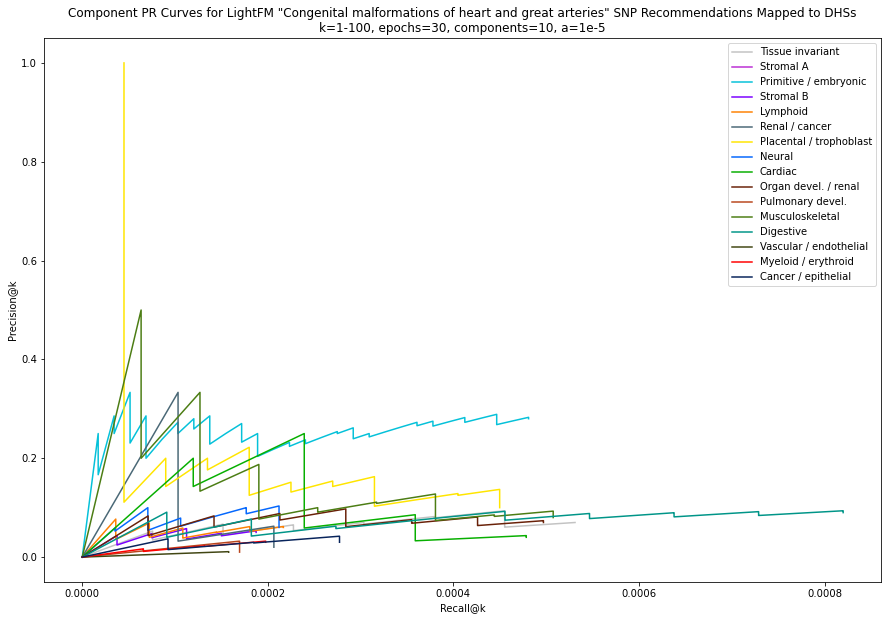

In [20]:
fig = plt.figure(figsize=(15,10))
fig.patch.set_facecolor('white')
for i in range(len(comps)):
    plt.plot(CONGEN_HEART_ARTER_all_comps_recall_100[i], CONGEN_HEART_ARTER_all_comps_precision_100[i], color=color[i])
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.legend(comps)
plt.title('Component PR Curves for LightFM "Congenital malformations of heart and great arteries" SNP Recommendations Mapped to DHSs\nk=1-100, epochs=30, components=10, a=1e-5')

In [3]:
#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision_multiple_k(rec_info_comps, target_comp, k_vals):
    comps = np.array(rec_info_comps)
    comps_np = np.where(comps == target_comp, 1, 0)
    total_of_comp = np.sum(comps_np)
    count_list = []
    for k in k_vals:
        comp_k = comps_np[:k]
        count = np.sum(comp_k)
        count_list.append(count)
    counts = np.array(count_list)
    precision = counts/k_vals
    recall = counts/total_of_comp
    return precision, recall

**load in merged SNP recs/DHSs through bedops**

In [4]:
trait_names_4c = ['lupus', 'mean_corpuscular_haemoglobin_concentration', 'QRS_duration', 'Corneal_hysteresis_left', 'unsuccessful_stop_smoking_attempts', 'female_genital_prolapse', 'father_chronic_bronchitis_emphysema']
trait_names_4c_extra = ['reticulocyte_count', 'pulse_rate_automated_reading']
trait_names_4c.extend(trait_names_4c_extra)

In [6]:
# trait_SNP_DHS_recs = []
# for trait in trait_names_4c:
#     trait_list = []
#     file_path = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_' + trait + '_to_DHS_CT20211122.scoreSorted.txt')
#     with open(file_path) as f:
#         SNPs = []
#         DHSs = []
#         for line in f:
#             line = line.strip('\n')
#             line = line.split('|')
#             SNP = line[0]
#             DHS = line[1]
#             multiple_DHS = DHS.split(';')
#             for i in range(len(multiple_DHS)):
#                 multiple_DHS[i] = multiple_DHS[i].split('\t')
#             SNP = SNP.split('\t')
#             SNPs.append(SNP)
#             DHSs.append(multiple_DHS)
#         trait_list.append(SNPs)
#         trait_list.append(DHSs)
#     trait_SNP_DHS_recs.append(trait_list)

In [7]:
# trait = trait_SNP_DHS_recs[0]
# trait[1][0][0]
# DHS_meta_dict['1.10011']

In [8]:
# for trait in trait_SNP_DHS_recs:
#     for DHSs in trait[1]:
#         for DHS in DHSs:
#             identifier = DHS[3]
#             DHS.append(DHS_meta_dict[identifier])

In [9]:
# trait_SNP_DHS_recs[0][1][3]

In [5]:
to_dataframe = []
for trait in trait_names_4c:
    print(trait)
    to_dataframe_trait = []
#     trait_list = []
    file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d20_reg1e-05_lr01_rec_info_' + trait + '_to_DHS_CT20211203.scoreSorted.txt')
    with open(file_path) as f:
        for line in f:
            line = line.strip('\n')
            line = line.split('|')
            SNP = line[0]
            DHS = line[1]
            SNP = SNP.split('\t')
            to_dataframe_list = SNP
            multiple_DHS = DHS.split(';')
            for i in range(len(multiple_DHS)):
                multiple_DHS[i] = multiple_DHS[i].split('\t')
                to_dataframe_list.extend(multiple_DHS[i])
            to_dataframe_trait.append(to_dataframe_list)
    to_dataframe.append(to_dataframe_trait)          

lupus
mean_corpuscular_haemoglobin_concentration
QRS_duration
Corneal_hysteresis_left
unsuccessful_stop_smoking_attempts
female_genital_prolapse
father_chronic_bronchitis_emphysema
reticulocyte_count
pulse_rate_automated_reading


In [32]:
# trait_names_4c_extra = ['reticulocyte_count', 'pulse_rate_automated_reading']
# trait_names_4c.extend(trait_names_4c_extra)

In [33]:
# for trait in trait_names_4c_extra:
#     to_dataframe_trait = []
# #     trait_list = []
#     file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_' + trait + '_to_DHS_CT20211124.scoreSorted.txt')
#     with open(file_path) as f:
#         for line in f:
#             line = line.strip('\n')
#             line = line.split('|')
#             SNP = line[0]
#             DHS = line[1]
#             SNP = SNP.split('\t')
#             to_dataframe_list = SNP
#             multiple_DHS = DHS.split(';')
#             for i in range(len(multiple_DHS)):
#                 multiple_DHS[i] = multiple_DHS[i].split('\t')
#                 to_dataframe_list.extend(multiple_DHS[i])
#             to_dataframe_trait.append(to_dataframe_list)
#     to_dataframe.append(to_dataframe_trait)   

In [6]:
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']
len(cols)

21

In [7]:
lupus_df = pd.DataFrame(to_dataframe[0], columns = cols)
mean_corpuscular_haemoglobin_concentration_df = pd.DataFrame(to_dataframe[1], columns = cols)
QRS_duration_df = pd.DataFrame(to_dataframe[2], columns = cols)
Corneal_hysteresis_left_df = pd.DataFrame(to_dataframe[3], columns = cols)
unsuccessful_stop_smoking_attempts_df = pd.DataFrame(to_dataframe[4], columns = cols)
female_genital_prolapse_df = pd.DataFrame(to_dataframe[5], columns = cols)
father_chronic_bronchitis_emphysema_df = pd.DataFrame(to_dataframe[6], columns = cols)
reticulocyte_count_df = pd.DataFrame(to_dataframe[7], columns = cols)
pulse_rate_automated_reading_df = pd.DataFrame(to_dataframe[8], columns = cols)

In [10]:
DHS_meta = DHS_metadata[['identifier', 'component']]
DHS_meta['ind'] = DHS_meta.index
DHS_meta = DHS_meta.set_index('identifier')
DHS_meta_ind = DHS_meta['ind']
DHS_meta_ind_dict = DHS_meta_ind.to_dict()
DHS_meta_comp = DHS_meta['component']
DHS_meta_comp_dict = DHS_meta_comp.to_dict()

/tmp/ipykernel_191919/2249616465.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DHS_meta['ind'] = DHS_meta.index


In [11]:
for i in range(1, 5):
    lupus_dhs_id = np.array(list(lupus_df['dhs' + str(i) + ' id']))
    lupus_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(lupus_dhs_id)
    lupus_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(lupus_dhs_id)
    lupus_df['dhs' + str(i) + ' ind'] = lupus_dhs_ind
    lupus_df['dhs' + str(i) + ' comp'] = lupus_dhs_comp
    
for i in range(1, 5):
    mean_corpuscular_haemoglobin_concentration_dhs_id = np.array(list(mean_corpuscular_haemoglobin_concentration_df['dhs' + str(i) + ' id']))
    mean_corpuscular_haemoglobin_concentration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_df['dhs' + str(i) + ' ind'] = mean_corpuscular_haemoglobin_concentration_dhs_ind
    mean_corpuscular_haemoglobin_concentration_df['dhs' + str(i) + ' comp'] = mean_corpuscular_haemoglobin_concentration_dhs_comp
    
for i in range(1, 5):
    QRS_duration_dhs_id = np.array(list(QRS_duration_df['dhs' + str(i) + ' id']))
    QRS_duration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(QRS_duration_dhs_id)
    QRS_duration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(QRS_duration_dhs_id)
    QRS_duration_df['dhs' + str(i) + ' ind'] = QRS_duration_dhs_ind
    QRS_duration_df['dhs' + str(i) + ' comp'] = QRS_duration_dhs_comp

for i in range(1, 5):
    Corneal_hysteresis_left_dhs_id = np.array(list(Corneal_hysteresis_left_df['dhs' + str(i) + ' id']))
    Corneal_hysteresis_left_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(Corneal_hysteresis_left_dhs_id)
    Corneal_hysteresis_left_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(Corneal_hysteresis_left_dhs_id)
    Corneal_hysteresis_left_df['dhs' + str(i) + ' ind'] = Corneal_hysteresis_left_dhs_ind
    Corneal_hysteresis_left_df['dhs' + str(i) + ' comp'] = Corneal_hysteresis_left_dhs_comp
    
for i in range(1, 5):
    unsuccessful_stop_smoking_attempts_dhs_id = np.array(list(unsuccessful_stop_smoking_attempts_df['dhs' + str(i) + ' id']))
    unsuccessful_stop_smoking_attempts_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(unsuccessful_stop_smoking_attempts_dhs_id)
    unsuccessful_stop_smoking_attempts_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(unsuccessful_stop_smoking_attempts_dhs_id)
    unsuccessful_stop_smoking_attempts_df['dhs' + str(i) + ' ind'] = unsuccessful_stop_smoking_attempts_dhs_ind
    unsuccessful_stop_smoking_attempts_df['dhs' + str(i) + ' comp'] = unsuccessful_stop_smoking_attempts_dhs_comp
    
for i in range(1, 5):
    female_genital_prolapse_dhs_id = np.array(list(female_genital_prolapse_df['dhs' + str(i) + ' id']))
    female_genital_prolapse_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(female_genital_prolapse_dhs_id)
    female_genital_prolapse_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(female_genital_prolapse_dhs_id)
    female_genital_prolapse_df['dhs' + str(i) + ' ind'] = female_genital_prolapse_dhs_ind
    female_genital_prolapse_df['dhs' + str(i) + ' comp'] = female_genital_prolapse_dhs_comp
    
for i in range(1, 5):
    father_chronic_bronchitis_emphysema_dhs_id = np.array(list(father_chronic_bronchitis_emphysema_df['dhs' + str(i) + ' id']))
    father_chronic_bronchitis_emphysema_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(father_chronic_bronchitis_emphysema_dhs_id)
    father_chronic_bronchitis_emphysema_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(father_chronic_bronchitis_emphysema_dhs_id)
    father_chronic_bronchitis_emphysema_df['dhs' + str(i) + ' ind'] = father_chronic_bronchitis_emphysema_dhs_ind
    father_chronic_bronchitis_emphysema_df['dhs' + str(i) + ' comp'] = father_chronic_bronchitis_emphysema_dhs_comp
    
for i in range(1, 2): #(1, 5)
    reticulocyte_count_dhs_id = np.array(list(reticulocyte_count_df['dhs' + str(i) + ' id']))
    reticulocyte_count_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(reticulocyte_count_dhs_id)
    reticulocyte_count_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(reticulocyte_count_dhs_id)
    reticulocyte_count_df['dhs' + str(i) + ' ind'] = reticulocyte_count_dhs_ind
    reticulocyte_count_df['dhs' + str(i) + ' comp'] = reticulocyte_count_dhs_comp
    
for i in range(1, 5):
    pulse_rate_automated_reading_dhs_id = np.array(list(pulse_rate_automated_reading_df['dhs' + str(i) + ' id']))
    pulse_rate_automated_reading_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_df['dhs' + str(i) + ' ind'] = pulse_rate_automated_reading_dhs_ind
    pulse_rate_automated_reading_df['dhs' + str(i) + ' comp'] = pulse_rate_automated_reading_dhs_comp

In [12]:
lupus_comps = list(lupus_df['dhs1 comp'])
mean_corpuscular_haemoglobin_concentration_comps = list(mean_corpuscular_haemoglobin_concentration_df['dhs1 comp'])
QRS_duration_comps = list(QRS_duration_df['dhs1 comp'])
Corneal_hysteresis_left_comps = list(Corneal_hysteresis_left_df['dhs1 comp'])
unsuccessful_stop_smoking_attempts_comps = list(unsuccessful_stop_smoking_attempts_df['dhs1 comp'])
female_genital_prolapse_comps = list(female_genital_prolapse_df['dhs1 comp'])
father_chronic_bronchitis_emphysema_comps = list(father_chronic_bronchitis_emphysema_df['dhs1 comp'])
reticulocyte_count_comps = list(reticulocyte_count_df['dhs1 comp'])
pulse_rate_automated_reading_comps = list(pulse_rate_automated_reading_df['dhs1 comp'])

all_4c_comps = [lupus_comps, mean_corpuscular_haemoglobin_concentration_comps, QRS_duration_comps, Corneal_hysteresis_left_comps, unsuccessful_stop_smoking_attempts_comps, female_genital_prolapse_comps, father_chronic_bronchitis_emphysema_comps, reticulocyte_count_comps, pulse_rate_automated_reading_comps]

In [13]:
all_4c_comps_precision = []
all_4c_comps_recall = []
for i in range(len(all_4c_comps)):
    k_vals = list(range(1, 1000))
    k_vals.extend(list(np.arange(1000, len(all_4c_comps[i]), 1000)))
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        comp_precision, comp_recall = component_precision_multiple_k(all_4c_comps[i], comp, k_vals)
        all_comps_precision.append(comp_precision)
        all_comps_recall.append(comp_recall)
    all_4c_comps_precision.append(all_comps_precision)
    all_4c_comps_recall.append(all_comps_recall)

In [14]:
all_4c_comps_precision_100 = []
all_4c_comps_recall_100 = []
for i in range(len(all_4c_comps)):
    k_vals = list(range(1, 1000))
    k_vals.extend(list(np.arange(1000, len(all_4c_comps[i]), 1000)))
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        comp_precision, comp_recall = component_precision_multiple_k(all_4c_comps[i], comp, k_vals[:100])
        all_comps_precision.append(comp_precision)
        all_comps_recall.append(comp_recall)
    all_4c_comps_precision_100.append(all_comps_precision)
    all_4c_comps_recall_100.append(all_comps_recall)

In [15]:
trait_full_names_4c = ['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle', 'Mean corpuscular haemoglobin concentration', 'QRS duration', 'Corneal hysteresis (left)', 'Number of unsuccessful stop-smoking attempts', 'Diagnoses - main ICD10: N81 Female genital prolapse', 'Illnesses of father: Chronic bronchitis/emphysema', 'Reticulocyte count', 'Pulse rate, automated reading']

Text(0.465, 1.03, 'Component Precision-Recall Curves for Top Traits of Each Component in Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=1e-5, learning rate=0.01')

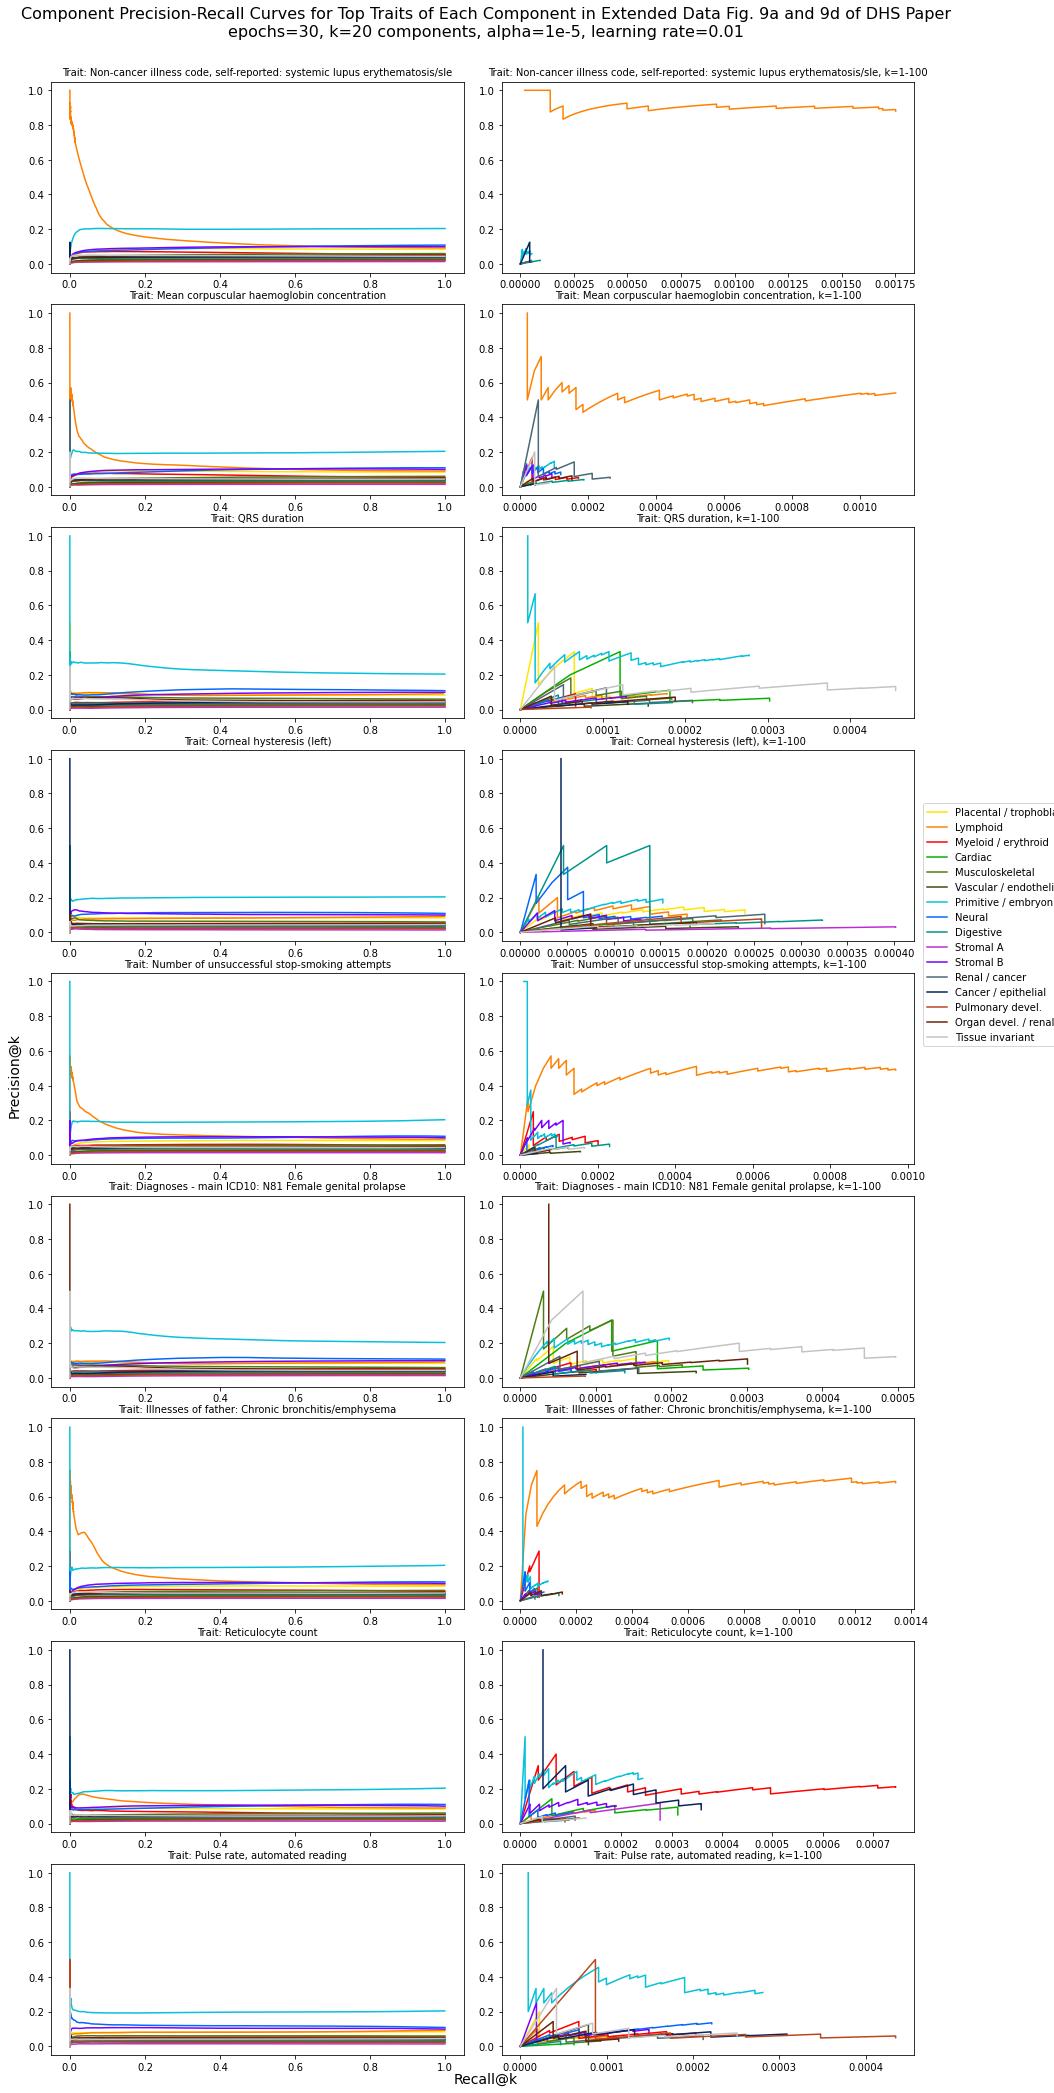

In [17]:
fig, axes = plt.subplots(nrows=9, ncols=2, figsize=(14,28))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(18)):
    if ind%2 == 0:
        ind = ind // 2
        for i in range(len(comps)):
            ax.plot(all_4c_comps_recall[ind][i], all_4c_comps_precision[ind][i], color=color[i])
        ax.set_title('Trait: ' + trait_full_names_4c[ind], fontsize=10)
    else:
        ind = ind // 2
        for i in range(len(comps)):
            ax.plot(all_4c_comps_recall_100[ind][i], all_4c_comps_precision_100[ind][i], color=color[i])
        ax.set_title('Trait: ' + trait_full_names_4c[ind] + ', k=1-100', fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component Precision-Recall Curves for Top Traits of Each Component in Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=1e-5, learning rate=0.01', fontsize=16, x=0.465, y=1.03)#GWAS_e30_d20_reg1e-05_lr01_rec_info


In [20]:
#merging dataframes together to compare snp ranks for each trait
lupus_df['lupus rank'] = lupus_df.index
mean_corpuscular_haemoglobin_concentration_df['mchc rank'] = mean_corpuscular_haemoglobin_concentration_df.index
QRS_duration_df['QRS rank'] = QRS_duration_df.index
Corneal_hysteresis_left_df['corneal hysteresis rank'] = Corneal_hysteresis_left_df.index
unsuccessful_stop_smoking_attempts_df['stop smoking rank'] = unsuccessful_stop_smoking_attempts_df.index
female_genital_prolapse_df['genital prolapse rank'] = female_genital_prolapse_df.index
father_chronic_bronchitis_emphysema_df['chronic bronchitis rank'] = father_chronic_bronchitis_emphysema_df.index
reticulocyte_count_df['reticulocyte count rank'] = reticulocyte_count_df.index
pulse_rate_automated_reading_df['pulse rate rank'] = pulse_rate_automated_reading_df.index

merged_df = lupus_df.merge(mean_corpuscular_haemoglobin_concentration_df[['reference snp cluster ID', 'mchc rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(QRS_duration_df[['reference snp cluster ID', 'QRS rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(Corneal_hysteresis_left_df[['reference snp cluster ID', 'corneal hysteresis rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(unsuccessful_stop_smoking_attempts_df[['reference snp cluster ID', 'stop smoking rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(female_genital_prolapse_df[['reference snp cluster ID', 'genital prolapse rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(father_chronic_bronchitis_emphysema_df[['reference snp cluster ID', 'chronic bronchitis rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(reticulocyte_count_df[['reference snp cluster ID', 'reticulocyte count rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(pulse_rate_automated_reading_df[['reference snp cluster ID', 'pulse rate rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')

In [29]:
merged_df['ranks averaged'] = (merged_df['lupus rank'] + merged_df['mchc rank'] + merged_df['QRS rank'] + merged_df['corneal hysteresis rank'] + merged_df['stop smoking rank'] + merged_df['genital prolapse rank'] + merged_df['chronic bronchitis rank'] + merged_df['reticulocyte count rank'] + merged_df['pulse rate rank'])/9
merged_df

,snp chr,snp start,snp end,pred score,reference snp cluster ID,dhs1 chr,dhs1 start,dhs1 end,dhs1 id,dhs2 chr,...,lupus rank,mchc rank,QRS rank,corneal hysteresis rank,stop smoking rank,genital prolapse rank,chronic bronchitis rank,reticulocyte count rank,pulse rate rank,ranks averaged
0,chr11,121129714,121129715,-0.034829836,rs111759871,chr11,121129560,121129800,11.906882,None,...,0,3,3,3,63,3,4,3,3,9.444444
1,chr12,104309927,104309928,-0.034912873,rs560473142,chr12,104309853,104310100,12.804293,None,...,1,4,4,4,64,4,5,4,4,10.444444
2,chr12,53504730,53504731,-0.03508964,rs200766710,chr12,53504126,53504820,12.4612992,None,...,2,5,5,5,65,5,6,5,5,11.444444
3,chr3,44631195,44631196,-0.035306234,rs768709603,chr3,44631095,44631250,3.302632,None,...,3,6,6,6,66,6,7,6,6,12.444444
4,chr9,114377461,114377462,-0.03570051,rs144197220,chr9,114377380,114377560,9.8436877,None,...,4,7,7,7,67,7,8,7,7,13.444444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
514023,chr3,183769716,183769717,-0.055233076,3:183487504_CAG_C,chr3,183769540,183769720,3.934076,None,...,546458,539739,547651,546321,547707,547485,547777,526033,540515,543298.444444
514024,chr11,94342486,94342487,-0.055287957,rs536567434,chr11,94342340,94342512,11.72849,None,...,546459,539740,547652,546322,547708,547486,547778,526034,540516,543299.444444
514025,chr10,93764558,93764559,-0.05530698,rs190638599,chr10,93764540,93764740,10.7304996,None,...,546460,539741,547653,546323,547709,547487,547779,526035,540517,543300.444444
514026,chr3,69171793,69171794,-0.055427983,rs147379378,chr3,69171480,69171860,3.413973,None,...,546461,539742,547654,546324,547710,547488,547780,526036,540518,543301.444444


In [37]:
ranks_averaged_list = list(merged_df['ranks averaged'])
lupus_ranks = list(merged_df['lupus rank'])

Text(0.5, 1.0, 'Comparing SNP (Mapped to DHS) Recommendation Rankings from 9 Traits from Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=5e-4, learning rate=0.01')

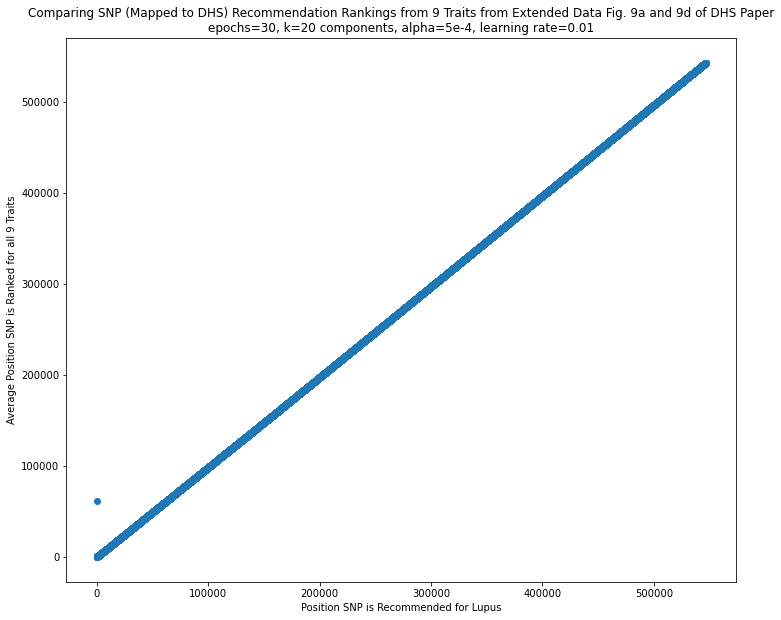

In [38]:
fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
plt.scatter(lupus_ranks, ranks_averaged_list)

plt.xlabel('Position SNP is Recommended for Lupus')
plt.ylabel('Average Position SNP is Ranked for all 9 Traits')
plt.title('Comparing SNP (Mapped to DHS) Recommendation Rankings from 9 Traits from Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=5e-4, learning rate=0.01')

**Comparing component breakdown for each trait**

In [22]:
lupus_comp_breakdown = []
for comp in comps:
    lupus_comp_breakdown.append(len(lupus_df[lupus_df['dhs1 comp']==comp])/len(lupus_df))
    
mean_corpuscular_haemoglobin_concentration_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_df[mean_corpuscular_haemoglobin_concentration_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_df))
    
QRS_duration_comp_breakdown = []
for comp in comps:
    QRS_duration_comp_breakdown.append(len(QRS_duration_df[QRS_duration_df['dhs1 comp']==comp])/len(QRS_duration_df))
    
Corneal_hysteresis_left_comp_breakdown = []
for comp in comps:
    Corneal_hysteresis_left_comp_breakdown.append(len(Corneal_hysteresis_left_df[Corneal_hysteresis_left_df['dhs1 comp']==comp])/len(Corneal_hysteresis_left_df))
    
unsuccessful_stop_smoking_attempts_comp_breakdown = []
for comp in comps:
    unsuccessful_stop_smoking_attempts_comp_breakdown.append(len(unsuccessful_stop_smoking_attempts_df[unsuccessful_stop_smoking_attempts_df['dhs1 comp']==comp])/len(unsuccessful_stop_smoking_attempts_df))
    
female_genital_prolapse_comp_breakdown = []
for comp in comps:
    female_genital_prolapse_comp_breakdown.append(len(female_genital_prolapse_df[female_genital_prolapse_df['dhs1 comp']==comp])/len(female_genital_prolapse_df))
    
father_chronic_bronchitis_emphysema_comp_breakdown = []
for comp in comps:
    father_chronic_bronchitis_emphysema_comp_breakdown.append(len(father_chronic_bronchitis_emphysema_df[father_chronic_bronchitis_emphysema_df['dhs1 comp']==comp])/len(father_chronic_bronchitis_emphysema_df))   

reticulocyte_count_comp_breakdown = []
for comp in comps:
    reticulocyte_count_comp_breakdown.append(len(reticulocyte_count_df[reticulocyte_count_df['dhs1 comp']==comp])/len(reticulocyte_count_df))

pulse_rate_automated_reading_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_comp_breakdown.append(len(pulse_rate_automated_reading_df[pulse_rate_automated_reading_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_df)) 

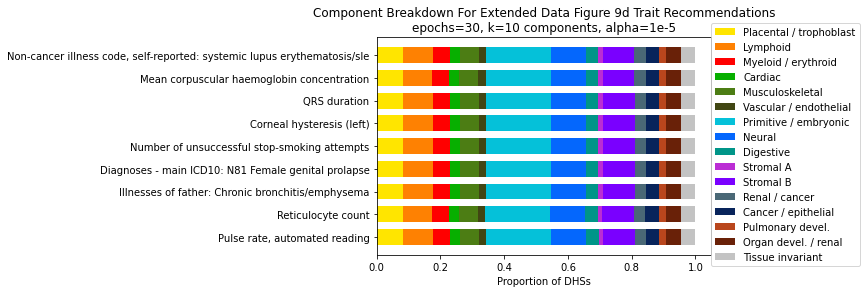

In [25]:
dataset = trait_full_names_4c
width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(pulse_rate_automated_reading_comp_breakdown)):
    plt.barh(dataset[8], pulse_rate_automated_reading_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_comp_breakdown[i]

left_num = 0
for i in range(len(reticulocyte_count_comp_breakdown)):
    plt.barh(dataset[7], reticulocyte_count_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += reticulocyte_count_comp_breakdown[i]

left_num = 0
for i in range(len(father_chronic_bronchitis_emphysema_comp_breakdown)):
    plt.barh(dataset[6], father_chronic_bronchitis_emphysema_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += father_chronic_bronchitis_emphysema_comp_breakdown[i]

left_num = 0
for i in range(len(female_genital_prolapse_comp_breakdown)):
    plt.barh(dataset[5], female_genital_prolapse_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += female_genital_prolapse_comp_breakdown[i]

left_num = 0
for i in range(len(unsuccessful_stop_smoking_attempts_comp_breakdown)):
    plt.barh(dataset[4], unsuccessful_stop_smoking_attempts_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += unsuccessful_stop_smoking_attempts_comp_breakdown[i]

left_num = 0
for i in range(len(Corneal_hysteresis_left_comp_breakdown)):
    plt.barh(dataset[3], Corneal_hysteresis_left_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += Corneal_hysteresis_left_comp_breakdown[i]

left_num = 0
for i in range(len(QRS_duration_comp_breakdown)):
    plt.barh(dataset[2], QRS_duration_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += QRS_duration_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_comp_breakdown)):
    plt.barh(dataset[1], mean_corpuscular_haemoglobin_concentration_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_comp_breakdown[i]
    
left_num = 0
for i in range(len(lupus_comp_breakdown)):
    plt.barh(dataset[0], lupus_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_comp_breakdown[i]



plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For Extended Data Figure 9d Trait Recommendations\nepochs=30, k=10 components, alpha=1e-5')
plt.legend(comps, loc = (1, -0.05))

plt.show()